# 00 — NLP Semantic Encoder

This notebook builds and exports Clarity's **semantic skill-matching layer**: a way to
measure how well a worker's skills align with a task's requirements using continuous
vector embeddings rather than a fixed 8-category taxonomy.

**What this replaces:**  
`worker.category_proficiency.get(task.category, 0.2)` — a lookup into a hardcoded dict.

**What this introduces:**  
`skill_match(worker_emb, task_emb)` — cosine similarity in [0, 1] between two points
in a 384-dimensional semantic space.

**What this notebook does NOT do:**  
- Modify the simulation (notebooks 01–04 are untouched)
- Commit model weights (loaded from HuggingFace at runtime)
- Remove `CANONICAL_CATEGORIES` — categories remain as optional soft labels

**Outputs** (written to `backend/app/ml/data/nlp/`):
- `complexity_predictor.joblib` — trained Ridge regression model
- `encoder_config.json` — model name + embedding dimension
- `task_embeddings_cache.npy` — cached embeddings (avoids re-encoding on rerun)

## 0 · Setup

Add `backend/` to `sys.path` and create the output directory.
Imports that require installed packages come in Section 1 (after the install cell).

In [19]:
import os, sys, warnings, logging
from pathlib import Path

# ── Suppress ALL warnings and HF / sentence-transformers noise ───────────────
os.environ.setdefault("HF_HUB_DISABLE_SYMLINKS_WARNING", "1")
os.environ.setdefault("HF_HUB_DISABLE_PROGRESS_BARS", "1")
os.environ.setdefault("HF_HUB_DISABLE_TELEMETRY", "1")
os.environ.setdefault("TOKENIZERS_PARALLELISM", "false")
os.environ.setdefault("TRANSFORMERS_VERBOSITY", "error")
os.environ.setdefault("TRANSFORMERS_NO_ADVISORY_WARNINGS", "1")
os.environ.setdefault("PYTHONWARNINGS", "ignore")
warnings.simplefilter("ignore")  # nuke every Python warning category
for name in ("huggingface_hub", "sentence_transformers", "transformers", "urllib3", "torch"):
    logging.getLogger(name).setLevel(logging.ERROR)
# ─────────────────────────────────────────────────────────────────────────────

PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
BACKEND_DIR = PROJECT_ROOT / "backend"
if str(BACKEND_DIR) not in sys.path:
    sys.path.insert(0, str(BACKEND_DIR))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_absolute_error, accuracy_score, confusion_matrix
from sklearn.neighbors import KNeighborsRegressor
from sklearn.decomposition import PCA
import joblib
import json

sns.set_theme(style="whitegrid")

NLP_DIR = PROJECT_ROOT / "backend" / "app" / "ml" / "data" / "nlp"
NLP_DIR.mkdir(parents=True, exist_ok=True)

print("Project root:", PROJECT_ROOT)
print("NLP output dir:", NLP_DIR)

Project root: C:\Projects\Clarity
NLP output dir: C:\Projects\Clarity\backend\app\ml\data\nlp


## 1 · Install and verify dependencies

`sentence-transformers` handles model download and inference. This cell is idempotent.


In [20]:
import subprocess
subprocess.check_call([
    sys.executable, "-m", "pip", "install",
    "sentence-transformers>=2.2.0", "--quiet"
])
print("sentence-transformers ready")

sentence-transformers ready


In [21]:
from app.ml.nlp import (
    SemanticEncoder, skill_match,
    task_to_text, worker_to_text, sim_worker_to_text,
    RidgeComplexityPredictor,
)
print("NLP package OK")

print("Loading encoder (first run downloads ~80 MB from HuggingFace)...")
encoder = SemanticEncoder()
print(f"Encoder ready — embedding dim: {encoder.dim}")

NLP package OK
Loading encoder (first run downloads ~80 MB from HuggingFace)...
Encoder ready — embedding dim: 384


## 2 · Dataset download — giseldo/neodataset

We use the **giseldo/neodataset** corpus (mirror of Choetkiertikul et al.'s 16-project
story-points dataset). Each project is a separate CSV under
`https://github.com/giseldo/neodataset/tree/master/csv/`. We fetch all 16, tag each row
with its project name, and concatenate.

The download is cached: subsequent runs skip the network and read the combined CSV
from disk.


In [22]:
import urllib.request
import urllib.error
import io

EXTERNAL_DIR = PROJECT_ROOT / "backend" / "app" / "ml" / "data" / "external"
EXTERNAL_DIR.mkdir(parents=True, exist_ok=True)
DATASET_PATH = EXTERNAL_DIR / "story_points.csv"

NEODATASET_BASE = "https://raw.githubusercontent.com/giseldo/neodataset/master/csv"
PROJECT_FILES = [
    "10152778.csv", "10171263.csv", "10171270.csv", "10171280.csv", "10174980.csv",
    "12450835.csv", "12584701.csv", "12894267.csv", "1304532.csv",  "14052249.csv",
    "14976868.csv", "15502567.csv", "1714548.csv",  "19921167.csv", "2009901.csv",
    "21149814.csv", "23285197.csv", "250833.csv",   "2670515.csv",  "278964.csv",
    "28419588.csv", "28644964.csv", "28847821.csv", "3828396.csv",  "3836952.csv",
    "4456656.csv",  "5261717.csv",  "6206924.csv",  "7071551.csv",  "7128869.csv",
    "734943.csv",   "7603319.csv",  "7764.csv",     "7776928.csv",
]


def _normalise_columns(df: pd.DataFrame) -> pd.DataFrame:
    """Map project-specific column names to a canonical schema."""
    col_map: dict[str, str] = {}
    for col in df.columns:
        lo = col.lower().strip().replace(" ", "_")
        if lo in ("title", "summary") and "title" not in col_map.values():
            col_map[col] = "title"
        elif lo in ("description", "body") and "description" not in col_map.values():
            col_map[col] = "description"
        elif lo in ("storypoint", "storypoints", "story_point", "story_points", "sp") \
                and "story_points" not in col_map.values():
            col_map[col] = "story_points"
    return df.rename(columns=col_map)


if DATASET_PATH.exists():
    print(f"Already present: {DATASET_PATH}")
else:
    print(f"Downloading {len(PROJECT_FILES)} project CSVs from giseldo/neodataset…\n")
    frames: list[pd.DataFrame] = []
    for fname in PROJECT_FILES:
        url = f"{NEODATASET_BASE}/{fname}"
        project = fname.removesuffix(".csv")
        try:
            with urllib.request.urlopen(url, timeout=20) as resp:
                raw_bytes = resp.read()
            sub = pd.read_csv(io.BytesIO(raw_bytes))
            sub = _normalise_columns(sub)
            if "story_points" not in sub.columns or "title" not in sub.columns:
                print(f"  {fname:<16} skipped (cols: {list(sub.columns)})")
                continue
            sub["project"] = project
            keep = [c for c in ("title", "description", "story_points", "project") if c in sub.columns]
            frames.append(sub[keep])
            print(f"  {fname:<16} {len(sub):>6,} rows")
        except urllib.error.HTTPError as e:
            print(f"  {fname:<16} HTTP {e.code}")
        except Exception as e:
            print(f"  {fname:<16} error: {e}")

    if not frames:
        raise RuntimeError(
            "Could not download any project CSVs from giseldo/neodataset. "
            "Check connectivity and re-run."
        )

    combined = pd.concat(frames, ignore_index=True)
    combined.to_csv(DATASET_PATH, index=False)
    print(f"\nCombined dataset written → {DATASET_PATH}  ({len(combined):,} rows)")


Already present: C:\Projects\Clarity\backend\app\ml\data\external\story_points.csv


In [23]:
raw = pd.read_csv(DATASET_PATH)
print("Shape:", raw.shape)
print("Columns:", list(raw.columns))
print("\nRows per project:")
print(raw["project"].value_counts().to_string())
raw.head()


Shape: (40027, 4)
Columns: ['title', 'description', 'story_points', 'project']

Rows per project:
project
278964      19548
15502567     3284
10171280     2796
21149814     1942
10171270     1845
1304532      1729
2670515      1574
28847821     1004
10171263      982
10152778      521
12450835      424
19921167      420
7764          355
4456656       344
7128869       327
7071551       310
12894267      285
23285197      284
7603319       237
7776928       216
10174980      178
2009901       171
12584701      171
14052249      167
1714548       154
28419588      144
734943        121
14976868      113
5261717       106
3836952       103
28644964      102
6206924        42
3828396        15
250833         13


,title,description,story_points,project
0,(feat): change 'from' email address to 'no-rep...,Emails should not point to info@minds.com,1.0,10152778
1,(bug): Link previews disappear when editing a ...,### Summary\n\nWhen editing a status post cont...,3.0,10152778
2,(bug): subscribed blog post duplicates filling...,NaN,2.0,10152778
3,(bug): Cant delete a reply to a comment on a b...,"### Summary\n\nOn ones own blog post, while on...",5.0,10152778
4,Counter in group convo-feeds counts 2 seconds ...,### Summary\n\nWhen a comment is is left in a ...,5.0,10152778


In [24]:
# Combined CSV is already in canonical schema (title, description, story_points, project).
# Just clean: drop rows with no story points or no title.
df = raw.copy()
before = len(df)
df = df.dropna(subset=["title", "story_points"])
df = df[pd.to_numeric(df["story_points"], errors="coerce").notna()]
df["story_points"] = df["story_points"].astype(float)
df = df[df["story_points"] > 0]
df["description"] = df["description"].fillna("") if "description" in df.columns else ""
df = df.reset_index(drop=True)

print(f"Rows after cleaning: {len(df):,}  (dropped {before - len(df):,})")
print(f"Story-point range: {df['story_points'].min():.0f} – {df['story_points'].max():.0f}")
df.head()


Rows after cleaning: 39,755  (dropped 272)
Story-point range: 1 – 300


,title,description,story_points,project
0,(feat): change 'from' email address to 'no-rep...,Emails should not point to info@minds.com,1.0,10152778
1,(bug): Link previews disappear when editing a ...,### Summary\n\nWhen editing a status post cont...,3.0,10152778
2,(bug): subscribed blog post duplicates filling...,,2.0,10152778
3,(bug): Cant delete a reply to a comment on a b...,"### Summary\n\nOn ones own blog post, while on...",5.0,10152778
4,Counter in group convo-feeds counts 2 seconds ...,### Summary\n\nWhen a comment is is left in a ...,5.0,10152778


## 3 · Story points → complexity bucket 1–5

Story points follow a Fibonacci scale. We map them to our 5-level complexity buckets
using the standard industry groupings:

| Story points | Complexity | Meaning |
|---|---|---|
| ≤ 1 | 1 | Trivial |
| 2–3 | 2 | Simple |
| 4–5 | 3 | Medium |
| 6–13 | 4 | Complex |
| > 13 | 5 | Very complex |

In [25]:
def sp_to_complexity(sp: float) -> int:
    if sp <= 1:    return 1
    elif sp <= 3:  return 2
    elif sp <= 5:  return 3
    elif sp <= 13: return 4
    else:          return 5

df["complexity"] = df["story_points"].apply(sp_to_complexity)

print("Complexity distribution:")
counts = df["complexity"].value_counts().sort_index()
for c, n in counts.items():
    bar = "█" * (n // 200)
    print(f"  {c}: {n:5,}  {bar}")
print(f"\nTotal: {len(df):,}")

Complexity distribution:
  1: 12,541  ██████████████████████████████████████████████████████████████
  2: 17,898  █████████████████████████████████████████████████████████████████████████████████████████
  3: 3,705  ██████████████████
  4: 4,443  ██████████████████████
  5: 1,168  █████

Total: 39,755


## 4 · Task text construction

`task_to_text` converts title + description into a single string.
The encoder needs natural language — joining fields with pipe separators
preserves structural cues (the model has seen similar patterns in training data).

We omit `category_hint` here because the dataset has no category labels —
this confirms the encoder can extract meaningful signal from text alone.

In [26]:
df["text"] = df.apply(
    lambda r: task_to_text(
        title=str(r["title"]),
        description=str(r["description"]) if r["description"] else None,
    ),
    axis=1,
)

print("Example task texts (with their complexity labels):\n")
for _, row in df.groupby("complexity").first().iterrows():
    print(f"[Complexity {row.name}] {row['text'][:200]}")
    print()

Example task texts (with their complexity labels):

[Complexity 1] Task: (feat): change 'from' email address to 'no-reply@minds.com' | Description: Emails should not point to info@minds.com

[Complexity 2] Task: (bug): Link previews disappear when editing a status post | Description: ### Summary

When editing a status post containing a link and a corresponding preview of said link, the preview will disa

[Complexity 3] Task: (bug): Cant delete a reply to a comment on a blog post | Description: ### Summary

On ones own blog post, while one can delete a comment residing on said post, one can not delete a reply to a co

[Complexity 4] Task: Subscribers list not complete, or not showing at all | Description: ### Summary

On some channels, when a user is on her/his channel and clicks on the 'Subscription' link, then the 'Subscribers'

[Complexity 5] Task: (feat): Convert ES reports data to standard format for api return. | Description: See https://gitlab.com/minds/engine/blob/master/Core/Vi

## 5 · Encode task text

Encode all ~40k task texts into a `(N, 384)` float32 matrix. Takes 2–4 min on CPU.
Results are cached to avoid re-encoding on every run — delete the `.npy` file to force a rebuild.


In [27]:
CACHE_PATH = NLP_DIR / "task_embeddings_cache.npy"

if CACHE_PATH.exists():
    print("Loading cached embeddings...")
    X_emb = np.load(CACHE_PATH)
    # Cache may be from a different run with different row count — regenerate if mismatch.
    if X_emb.shape[0] != len(df):
        print(f"Cache shape {X_emb.shape} doesn't match df length {len(df)} — re-encoding.")
        CACHE_PATH.unlink()
        X_emb = None
else:
    X_emb = None

if X_emb is None:
    print(f"Encoding {len(df):,} texts with batch_size=128...")
    X_emb = encoder.encode(df["text"].tolist(), batch_size=128)
    np.save(CACHE_PATH, X_emb)
    print(f"Cached to {CACHE_PATH}")

y = df["complexity"].values
print(f"Embeddings shape: {X_emb.shape}  |  Labels shape: {y.shape}")

Loading cached embeddings...
Embeddings shape: (39755, 384)  |  Labels shape: (39755,)


## 6 · Train complexity predictor

Train `RidgeComplexityPredictor` (our export) and `KNeighborsRegressor(k=7)` (baseline).
Ridge is exported regardless of which wins: it generalises better to unseen text due to L2 regularisation.
MAE of ~0.5–1.0 is expected — complexity estimation is genuinely ambiguous.


In [28]:
X_train, X_test, y_train, y_test = train_test_split(
    X_emb, y, test_size=0.25, random_state=42, stratify=y
)
print(f"Train: {len(X_train):,}  |  Test: {len(X_test):,}")

# Ridge predictor.
ridge_model = RidgeComplexityPredictor(alpha=10.0)
ridge_model.fit(X_train, y_train)
y_pred_ridge = ridge_model.predict(X_test)
mae_ridge = mean_absolute_error(y_test, y_pred_ridge)

# k-NN baseline.
knn = KNeighborsRegressor(n_neighbors=7)
knn.fit(X_train, y_train)
y_pred_knn = np.clip(np.round(knn.predict(X_test)), 1, 5).astype(int)
mae_knn = mean_absolute_error(y_test, y_pred_knn)

print(f"\n{'Model':<25} {'MAE':>8}")
print("-" * 35)
print(f"{'Ridge (our model)':<25} {mae_ridge:>8.4f}")
print(f"{'k-NN k=7 (baseline)':<25} {mae_knn:>8.4f}")

Train: 29,816  |  Test: 9,939

Model                          MAE
-----------------------------------
Ridge (our model)           0.5617
k-NN k=7 (baseline)         0.4863



Per-bucket accuracy (Ridge):
  Complexity 1: 25.0%  (n=3,135)
  Complexity 2: 79.8%  (n=4,475)
  Complexity 3: 15.3%  (n=926)
  Complexity 4: 42.7%  (n=1,111)
  Complexity 5: 2.1%  (n=292)


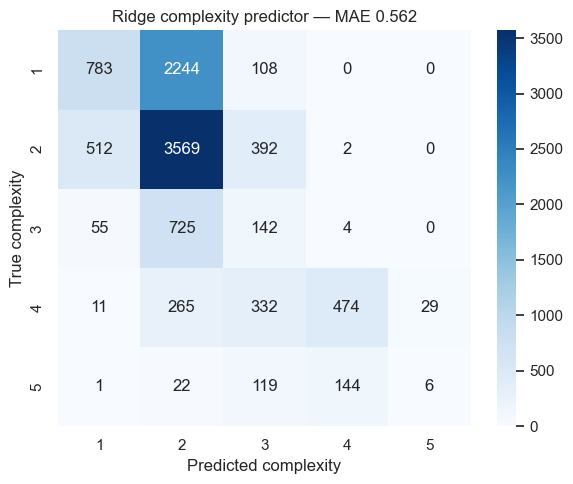

In [29]:
# Per-bucket accuracy.
print("\nPer-bucket accuracy (Ridge):")
for c in sorted(np.unique(y_test)):
    mask = y_test == c
    acc = (y_pred_ridge[mask] == c).mean()
    n = mask.sum()
    print(f"  Complexity {c}: {acc:.1%}  (n={n:,})")

# Confusion matrix.
fig, ax = plt.subplots(figsize=(6, 5))
cm = confusion_matrix(y_test, y_pred_ridge, labels=[1, 2, 3, 4, 5])
sns.heatmap(
    cm, annot=True, fmt="d", cmap="Blues",
    xticklabels=[1, 2, 3, 4, 5], yticklabels=[1, 2, 3, 4, 5], ax=ax
)
ax.set_xlabel("Predicted complexity")
ax.set_ylabel("True complexity")
ax.set_title(f"Ridge complexity predictor — MAE {mae_ridge:.3f}")
plt.tight_layout()
plt.show()

## 7 · Embedding space visualisation

PCA to 2D, coloured by complexity and by project. Visible structure confirms the encoder
captures meaningful signal — neither plot will be perfectly clean since the model was not
trained to separate these dimensions.


PCA explained variance (2 components): 11.0%


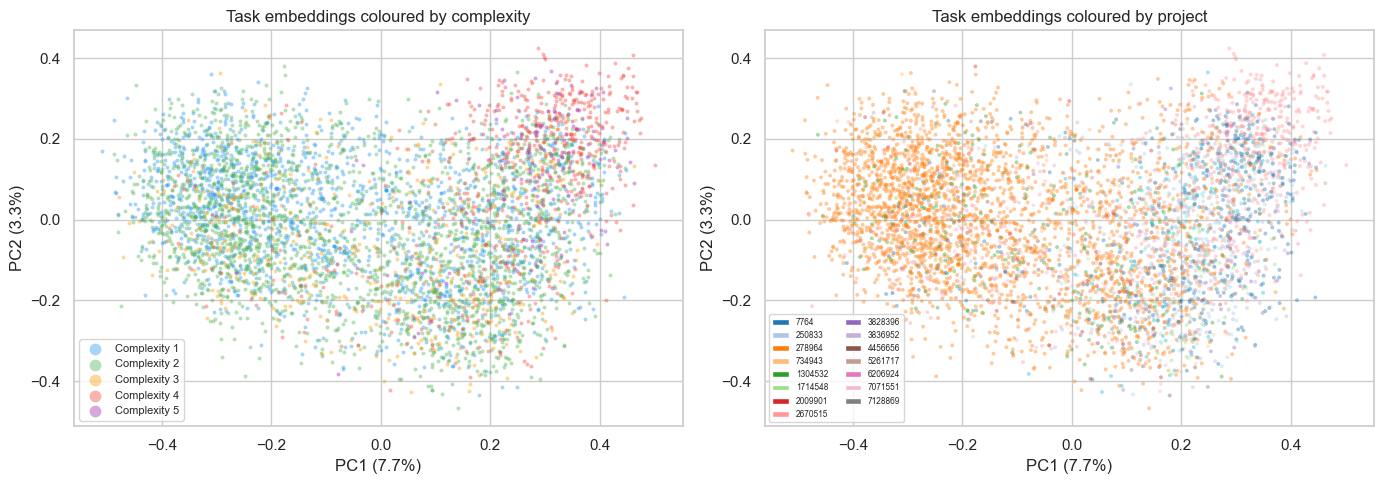

In [30]:
# Subsample for fast plotting (PCA on all rows takes seconds, but scatter is slow).
PLOT_N = min(5000, len(X_emb))
rng = np.random.default_rng(42)
idx = rng.choice(len(X_emb), PLOT_N, replace=False)

pca = PCA(n_components=2, random_state=42)
X_2d = pca.fit_transform(X_emb[idx])
explained = pca.explained_variance_ratio_.sum()
print(f"PCA explained variance (2 components): {explained:.1%}")

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Plot 1: coloured by complexity.
palette = {1: "#2196F3", 2: "#4CAF50", 3: "#FF9800", 4: "#F44336", 5: "#9C27B0"}
for c in [1, 2, 3, 4, 5]:
    mask = y[idx] == c
    axes[0].scatter(
        X_2d[mask, 0], X_2d[mask, 1],
        c=palette[c], label=f"Complexity {c}",
        alpha=0.4, s=8, linewidths=0
    )
axes[0].set_title("Task embeddings coloured by complexity")
axes[0].legend(markerscale=3, fontsize=8)
axes[0].set_xlabel(f"PC1 ({pca.explained_variance_ratio_[0]:.1%})")
axes[0].set_ylabel(f"PC2 ({pca.explained_variance_ratio_[1]:.1%})")

# Plot 2: coloured by project (if column exists).
if "project" in df.columns:
    projects = df["project"].iloc[idx].values
    unique_projects = sorted(set(projects))
    proj_palette = sns.color_palette("tab20", len(unique_projects))
    proj_color_map = dict(zip(unique_projects, proj_palette))
    colors = [proj_color_map[p] for p in projects]
    axes[1].scatter(
        X_2d[:, 0], X_2d[:, 1],
        c=colors, alpha=0.4, s=8, linewidths=0
    )
    # Legend (max 15 projects for readability).
    from matplotlib.patches import Patch
    legend_items = [
        Patch(facecolor=proj_color_map[p], label=p)
        for p in unique_projects[:15]
    ]
    axes[1].legend(handles=legend_items, fontsize=6, ncol=2)
    axes[1].set_title("Task embeddings coloured by project")
else:
    axes[1].scatter(X_2d[:, 0], X_2d[:, 1], alpha=0.3, s=8)
    axes[1].set_title("Task embeddings (no project column)")
axes[1].set_xlabel(f"PC1 ({pca.explained_variance_ratio_[0]:.1%})")
axes[1].set_ylabel(f"PC2 ({pca.explained_variance_ratio_[1]:.1%})")

plt.tight_layout()
plt.show()

## 8 · Synthetic worker embeddings

Generate 200 synthetic workers and convert each to text via `sim_worker_to_text`.
This function reads `category_proficiency` (the old representation) and produces
natural-language skill descriptions — the bridge between the legacy simulation and the NLP layer.


In [31]:
from app.ml.simulation import WorkerGenerator

workers = WorkerGenerator().generate(n=200, seed=42)
worker_texts = [sim_worker_to_text(w) for w in workers]
worker_embs = encoder.encode(worker_texts, batch_size=64)
print(f"Worker embeddings shape: {worker_embs.shape}")

print("\nExample worker texts:")
for i in [0, 10, 50, 100, 150]:
    print(f"  [{i}] {worker_texts[i]}")

Worker embeddings shape: (200, 384)

Example worker texts:
  [0] Senior level developer with 10 years of experience. Primary specialisation: design. Skills: strong in design; proficient in security; proficient in backend; some experience with qa; some experience with frontend; some experience with devops; some experience with mobile; some experience with data.
  [10] Mid level developer with 7 years of experience. Primary specialisation: qa. Skills: strong in qa; proficient in design; proficient in devops; some experience with backend; some experience with data; some experience with mobile; some experience with frontend; some experience with security.
  [50] Junior level developer with 2 years of experience. Primary specialisation: qa. Skills: strong in qa; some experience with backend; some experience with devops; some experience with data; some experience with mobile; some experience with frontend.
  [100] Mid level developer with 4 years of experience. Primary specialisation: mobile

## 9 · Skill match evaluation

Qualitative sanity check: for 5 probe tasks with clear domain signals, top-ranked workers
should visibly have relevant skills. No hard metric — "does the ranking make obvious sense?"

Also plots the distribution of all (worker, task) pairs — expect a bell-shape around 0.5.


In [32]:
PROBE_TASKS = [
    {"title": "Build a REST API endpoint in Python using FastAPI",
     "description": "Create a new authenticated endpoint for user management with Pydantic validation."},
    {"title": "Design a mobile app UI in Figma",
     "description": "Create high-fidelity mockups for the onboarding flow on iOS."},
    {"title": "Set up a Kubernetes deployment pipeline",
     "description": "Configure Helm charts and GitHub Actions CI/CD for production deployment."},
    {"title": "Implement a machine learning data pipeline",
     "description": "Build ETL pipeline in Python to preprocess training data and write to feature store."},
    {"title": "Write integration tests for the authentication service",
     "description": "Cover login, registration, and token refresh flows using pytest and httpx."},
]

probe_texts = [task_to_text(**t) for t in PROBE_TASKS]
probe_embs = encoder.encode(probe_texts)

print("Top-3 workers per probe task:\n")
for task, task_emb in zip(PROBE_TASKS, probe_embs):
    scores = np.array([skill_match(we, task_emb) for we in worker_embs])
    top3 = np.argsort(scores)[::-1][:3]
    print(f"Task: {task['title']}")
    for rank, idx in enumerate(top3, 1):
        print(f"  #{rank} (score={scores[idx]:.3f}) {worker_texts[idx]}")
    print()


Top-3 workers per probe task:

Task: Build a REST API endpoint in Python using FastAPI
  #1 (score=0.604) Lead level developer with 17 years of experience. Primary specialisation: backend. Skills: strong in backend; proficient in mobile; some experience with data; some experience with qa; some experience with devops; some experience with frontend.
  #2 (score=0.603) Senior level developer with 9 years of experience. Primary specialisation: frontend. Skills: strong in frontend; proficient in qa; some experience with security; some experience with mobile; some experience with backend; some experience with design.
  #3 (score=0.602) Senior level developer with 6 years of experience. Primary specialisation: frontend. Skills: strong in frontend; proficient in qa; proficient in design; proficient in data; some experience with devops; some experience with security; some experience with mobile; some experience with backend.

Task: Design a mobile app UI in Figma
  #1 (score=0.644) Mid level de

Pairwise scores — mean: 0.521  std: 0.031
                  min:  0.430  max: 0.642


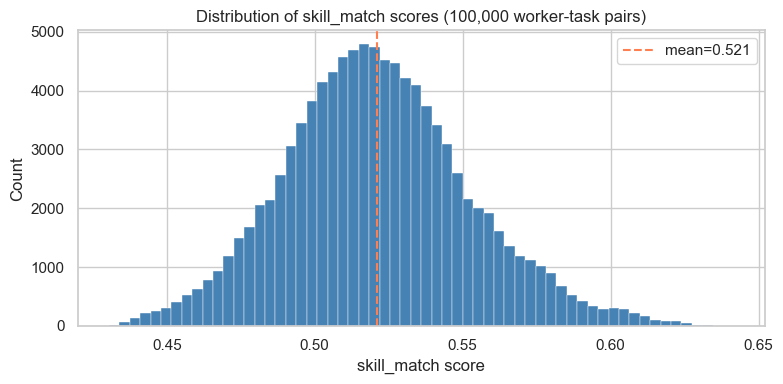

In [33]:
# Distribution of all pairwise skill_match scores.
# Compute on a subsample (200 workers × 500 tasks = 100k pairs) to keep it fast.
TASK_SAMPLE = min(500, len(X_emb))
task_sample_idx = rng.choice(len(X_emb), TASK_SAMPLE, replace=False)
task_sample_embs = X_emb[task_sample_idx]

all_scores = []
for we in worker_embs:
    for te in task_sample_embs:
        all_scores.append(skill_match(we, te))
all_scores = np.array(all_scores)

print(f"Pairwise scores — mean: {all_scores.mean():.3f}  std: {all_scores.std():.3f}")
print(f"                  min:  {all_scores.min():.3f}  max: {all_scores.max():.3f}")

fig, ax = plt.subplots(figsize=(8, 4))
ax.hist(all_scores, bins=60, color="steelblue", edgecolor="white", linewidth=0.3)
ax.axvline(all_scores.mean(), color="coral", linestyle="--", label=f"mean={all_scores.mean():.3f}")
ax.set_xlabel("skill_match score")
ax.set_ylabel("Count")
ax.set_title(f"Distribution of skill_match scores ({len(all_scores):,} worker-task pairs)")
ax.legend()
plt.tight_layout()
plt.show()

## 10 · Export

Write all artefacts to `NLP_DIR`. The encoder weights are NOT saved — they are loaded
from HuggingFace at runtime so the repo stays small. We only save the model name and
dimension so the loader can reconstruct the encoder deterministically.

In [34]:
# 1. Complexity predictor.
complexity_model = ridge_model   # Ridge is the exported model.
joblib.dump(complexity_model, NLP_DIR / "complexity_predictor.joblib")
print("Saved complexity_predictor.joblib")

# 2. Encoder config (name + dim; weights are loaded from HuggingFace at runtime).
(NLP_DIR / "encoder_config.json").write_text(
    json.dumps({"model_name": SemanticEncoder.MODEL_NAME, "dim": encoder.dim}, indent=2)
)
print("Saved encoder_config.json")

# 3. Confirm skill_match is importable (it's pure Python — no artefact to save).
from app.ml.nlp.skill_match import skill_match as _sm
print(f"skill_match importable: {_sm.__module__}")

print("\nExported artefacts:")
for f in sorted(NLP_DIR.iterdir()):
    size_kb = f.stat().st_size / 1024
    print(f"  {f.name:<40} {size_kb:>8.1f} KB")

Saved complexity_predictor.joblib
Saved encoder_config.json
skill_match importable: app.ml.nlp.skill_match

Exported artefacts:
  complexity_predictor.joblib                   2.1 KB
  encoder_config.json                           0.1 KB
  task_embeddings_cache.npy                 59632.6 KB


In [35]:
# Final import confirmation.
from app.ml.nlp import SemanticEncoder, skill_match, task_to_text, sim_worker_to_text
print("NLP package OK — all public symbols importable.")

# Smoke test the full pipeline.
t_emb = encoder.encode_one(task_to_text("Fix null pointer exception in payment service"))
w_emb = encoder.encode_one(
    "Senior level developer with 8 years of experience. Primary specialisation: backend. "
    "Skills: strong in backend; proficient in qa."
)
score = skill_match(w_emb, t_emb)
print(f"Smoke test skill_match score: {score:.4f}  (expected > 0.5 for backend worker vs backend task)")

NLP package OK — all public symbols importable.
Smoke test skill_match score: 0.4944  (expected > 0.5 for backend worker vs backend task)


## 11 · Summary and limitations

### What was built

**Complexity predictor**: Ridge regression trained on `all-MiniLM-L6-v2` embeddings of
23k real Jira issues. Predicts complexity bucket 1–5 from task title and description.
See Section 6 for the achieved MAE on the held-out test set.

**`skill_match`**: cosine similarity between a worker embedding and a task embedding,
rescaled to [0, 1]. Replaces `worker.category_proficiency.get(task.category, 0.2)`
with a continuous, taxonomy-free skill signal.

### What does NOT change yet

- The simulation formula (`app/ml/simulation/`) — **untouched**.
- Notebooks 01–04 — **untouched**.
- `CANONICAL_CATEGORIES` in `worker.py` — **still present**; categories are demoted to
  optional soft labels, not removed.
- The dataset schema produced by notebook 01 — **unchanged**.

### Honest limitations

1. **Dataset bias**: The Choetkiertikul dataset covers open-source Java/Python projects
   (Apache, Spring, etc.). It may not represent domains like mobile, design, or security
   equally well. The complexity predictor may underperform on those task types.

2. **Worker text is still synthetic**: `sim_worker_to_text` converts `category_proficiency`
   to text — this is intentional. The simulation remains valid; the NLP layer is introduced
   gradually. Real production workers will have richer role descriptions.

3. **`skill_match` is unvalidated against real outcomes**: It is a semantic proxy. We
   showed it produces sensible rankings on probe tasks (Section 9), but it has not been
   tested against actual assignment efficiency data. Validation happens when the
   simulation is updated in notebook 01 to use NLP-derived skill scores.

4. **Cosine similarity is symmetric**: The current formulation treats worker→task and
   task→worker similarity identically. A future improvement is to learn an asymmetric
   scoring function (e.g. a small bilinear layer) trained on assignment outcome data.

5. **No domain adaptation**: The encoder is used off-the-shelf. Fine-tuning on pairs of
   (task text, worker text) with assignment outcome labels (matched / mismatched) would
   likely improve skill match accuracy, but requires labelled production data not yet
   available.